# 416 – Multiclass QSVM

An SVM separates **two** classes.  For more classes, scikit-learn's `SVC` (and therefore
`QSVC`) uses the **one-vs-one** strategy: it trains one binary classifier for every *pair* of
classes – 3 classifiers for 3 classes – and lets them vote.  The quantum kernel from `415`
plugs in unchanged.

We use the **wine dataset** (3 grape cultivars, 13 chemical measurements), reduced to 2
principal components.

**You will learn to** apply a quantum kernel to a multiclass problem and read a confusion
matrix.

**Prerequisites:** `415`.

In [1]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')


Backend ready: LegacyAerSimulator('aer_simulator')


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit.circuit.library import zz_feature_map
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.utils import algorithm_globals
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.svm import SVC

## The data

Standardise → PCA to 2 components → scale to $[-1, 1]$; 24 training and 6 test samples per class.

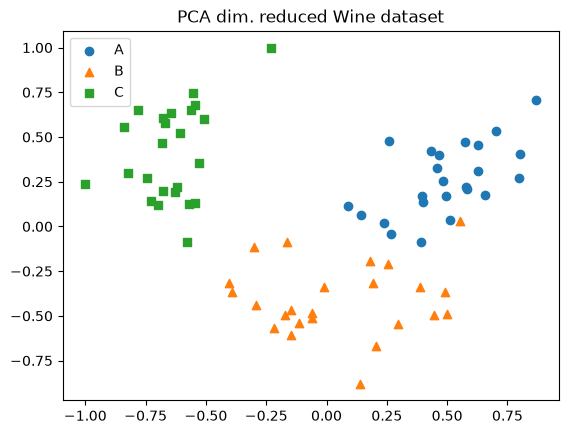

In [3]:
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

def prepare_dataset(loader, training_size, test_size, n, split, random_state):
    """Aqua's dataset recipe: standardise, PCA to n features, scale to [-1, 1], then take
    training_size / test_size samples per class. Returns feature/label arrays."""
    data, target = loader(return_X_y=True)
    x_train, x_test, y_train, y_test = train_test_split(data, target, test_size=split, random_state=random_state)
    std = StandardScaler().fit(x_train)
    x_train, x_test = std.transform(x_train), std.transform(x_test)
    pca = PCA(n_components=n).fit(x_train)
    x_train, x_test = pca.transform(x_train), pca.transform(x_test)
    minmax = MinMaxScaler((-1, 1)).fit(np.append(x_train, x_test, axis=0))
    x_train, x_test = minmax.transform(x_train), minmax.transform(x_test)
    def take(x, y, size):
        idx = np.concatenate([np.flatnonzero(y == c)[:size] for c in np.unique(target)])
        return x[idx], y[idx]
    return take(x_train, y_train, training_size) + take(x_test, y_test, test_size)

n = 2  # dimension of each data point
train_features, train_labels, test_features, test_labels = prepare_dataset(
    datasets.load_wine, training_size=24, test_size=6, n=n, split=0.1, random_state=7)
class_labels = ['A', 'B', 'C']
for c, marker in zip(range(3), ('o', '^', 's')):
    plt.scatter(*train_features[train_labels == c].T, marker=marker, label=class_labels[c])
plt.legend()
plt.title('PCA dim. reduced Wine dataset')
plt.show()
total_array = test_features

## Training and testing the multiclass QSVC

In [4]:
algorithm_globals.random_seed = 10598
feature_map = zz_feature_map(feature_dimension=train_features.shape[1],
                             reps=2, entanglement='linear')
qsvm = QSVC(quantum_kernel=FidelityQuantumKernel(feature_map=feature_map))
qsvm.fit(train_features, train_labels)
predicted_labels = qsvm.predict(test_features)
print(f'testing accuracy  : {qsvm.score(test_features, test_labels):.2f}')
print(f'true classes      : {[class_labels[i] for i in test_labels]}')
print(f'predicted classes : {[class_labels[i] for i in predicted_labels]}')

testing accuracy  : 0.73
true classes      : ['A', 'A', 'A', 'B', 'B', 'B', 'B', 'B', 'B', 'C', 'C', 'C', 'C', 'C', 'C']
predicted classes : ['A', 'A', 'A', 'B', 'B', 'B', 'C', 'B', 'B', 'A', 'C', 'C', 'A', 'A', 'C']


A **confusion matrix** shows which classes get mixed up: row = true class, column = predicted
class; everything off the diagonal is an error.

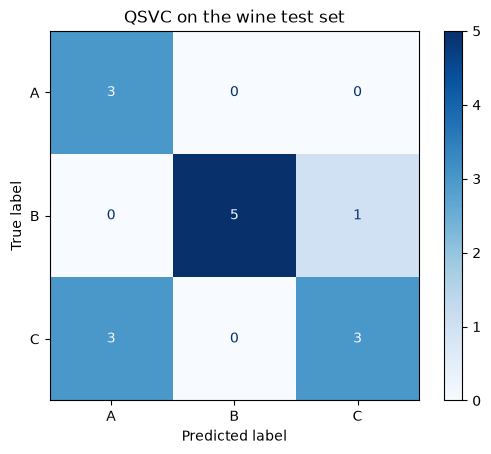

classical RBF-SVM testing accuracy: 1.00


In [5]:
ConfusionMatrixDisplay.from_predictions(test_labels, predicted_labels, display_labels=class_labels,
                                        cmap='Blues')
plt.title('QSVC on the wine test set')
plt.show()

svm = SVC(kernel='rbf', gamma='scale').fit(train_features, train_labels)
print(f'classical RBF-SVM testing accuracy: {svm.score(test_features, test_labels):.2f}')

## Key takeaways
* Multiclass kernel classification = several binary SVMs (one-vs-one) sharing one kernel.
* On the wine data the classical RBF kernel beats the quantum kernel – the same lesson as for
  the breast-cancer data in `415`: always compare with a classical baseline.

## Try it yourself
1. Use 3 PCA components (`n = 3`), i.e. 3 qubits.  Does the accuracy improve?
2. Swap in the iris dataset (`datasets.load_iris`), which also has 3 classes.
3. Use `QSVC(..., decision_function_shape='ovr')` and compare.

**Next:** the generative part of the path – `420-QGAN-01-Generator-vs-Discriminator-Toy`.
*(Optional warm-up: `303-Generate Random Variates`.)*